In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import random
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset

In [3]:
datasets.MNIST.mirrors = [
    "https://ossci-datasets.s3.amazonaws.com/mnist/",
    "https://storage.googleapis.com/cvdf-datasets/mnist/",
]
transform = transforms.Compose([
    transforms.ToTensor()
])
train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False)


In [4]:
class BaseMLP(nn.Module):
    def __init__(self, in_features=28*28, hidden_dim=128, num_classes=10):
        super().__init__()
        self.fc_1 = nn.Linear(in_features, hidden_dim)
        self.fc_2 = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)
        x = F.relu(self.fc_1(x))
        logits = self.fc_2(x)
        return logits

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Вычисления будут выполняться на: {device}")

Вычисления будут выполняться на: cuda


In [5]:
model = BaseMLP().to(device)
print(model)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

BaseMLP(
  (fc_1): Linear(in_features=784, out_features=128, bias=True)
  (fc_2): Linear(in_features=128, out_features=10, bias=True)
)


In [6]:
epochs = 5
os.makedirs("results", exist_ok=True)
print("Начало обучения baseline-модели...")
for epoch in range(1, epochs+1):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Эпоха [{epoch}/{epochs}] — Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_acc * 100:.2f}%")

torch.save(model.state_dict(), "results/base_mlp.pt")
print("Веса сохранены в results/base_mlp.pt")

Начало обучения baseline-модели...
Эпоха [1/5] — Train Loss: 0.3365, Train Accuracy: 90.86%
Эпоха [2/5] — Train Loss: 0.1472, Train Accuracy: 95.71%
Эпоха [3/5] — Train Loss: 0.1027, Train Accuracy: 96.93%
Эпоха [4/5] — Train Loss: 0.0786, Train Accuracy: 97.69%
Эпоха [5/5] — Train Loss: 0.0625, Train Accuracy: 98.14%
Веса сохранены в results/base_mlp.pt


Test Accuracy:        97.66%
Macro-Precision:      0.9766
Macro-Recall:         0.9764
Macro-F1 Score:       0.9764


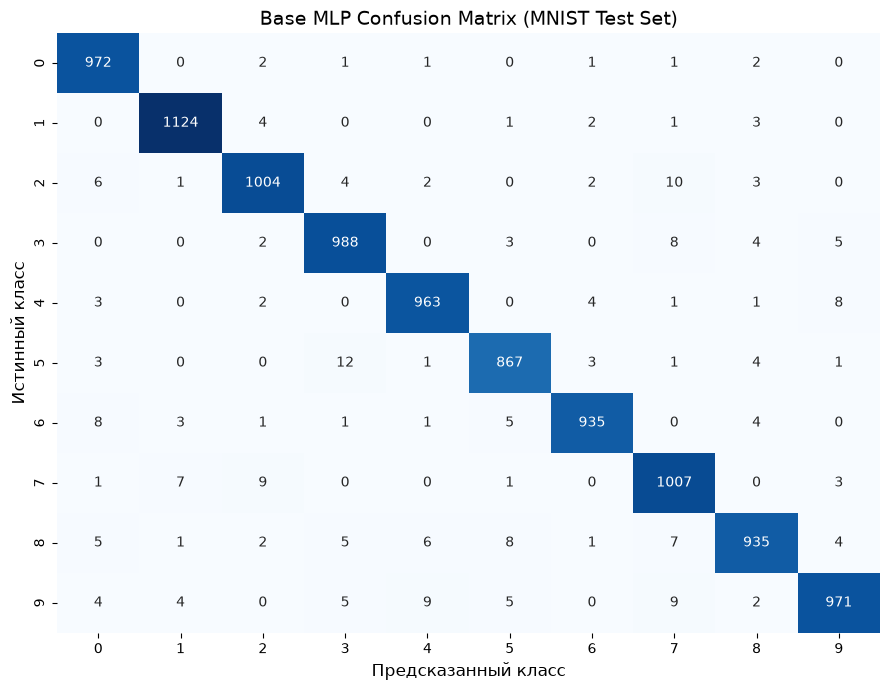

In [7]:
eval_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
eval_model = BaseMLP().to(eval_device)
weights_path = "results/base_mlp.pt"
if os.path.exists(weights_path):
    eval_model.load_state_dict(torch.load(weights_path, map_location=eval_device))
else:
    raise FileNotFoundError()
eval_model.eval()
all_preds = []
all_targets = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(eval_device)
        outputs = eval_model(images)
        preds = outputs.argmax(dim=1).cpu().numpy()
        
        all_preds.extend(preds)
        all_targets.extend(labels.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

acc = accuracy_score(all_targets, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(
    all_targets, all_preds, average='macro'
)
print("=" * 45)
print(f"Test Accuracy:        {acc * 100:.2f}%")
print(f"Macro-Precision:      {precision:.4f}")
print(f"Macro-Recall:         {recall:.4f}")
print(f"Macro-F1 Score:       {f1:.4f}")
print("=" * 45)
cm = confusion_matrix(all_targets, all_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Base MLP Confusion Matrix (MNIST Test Set)", fontsize=14)
plt.xlabel("Предсказанный класс", fontsize=12)
plt.ylabel("Истинный класс", fontsize=12)
plt.tight_layout()
plt.savefig("results/base_cm.png", dpi=300)
plt.show()


Поиск контрастных метаморфических нарушений...
Успешно собрано нарушений: 10 шт.
График нарушений сохранен в results/violations/top_10_violations.png


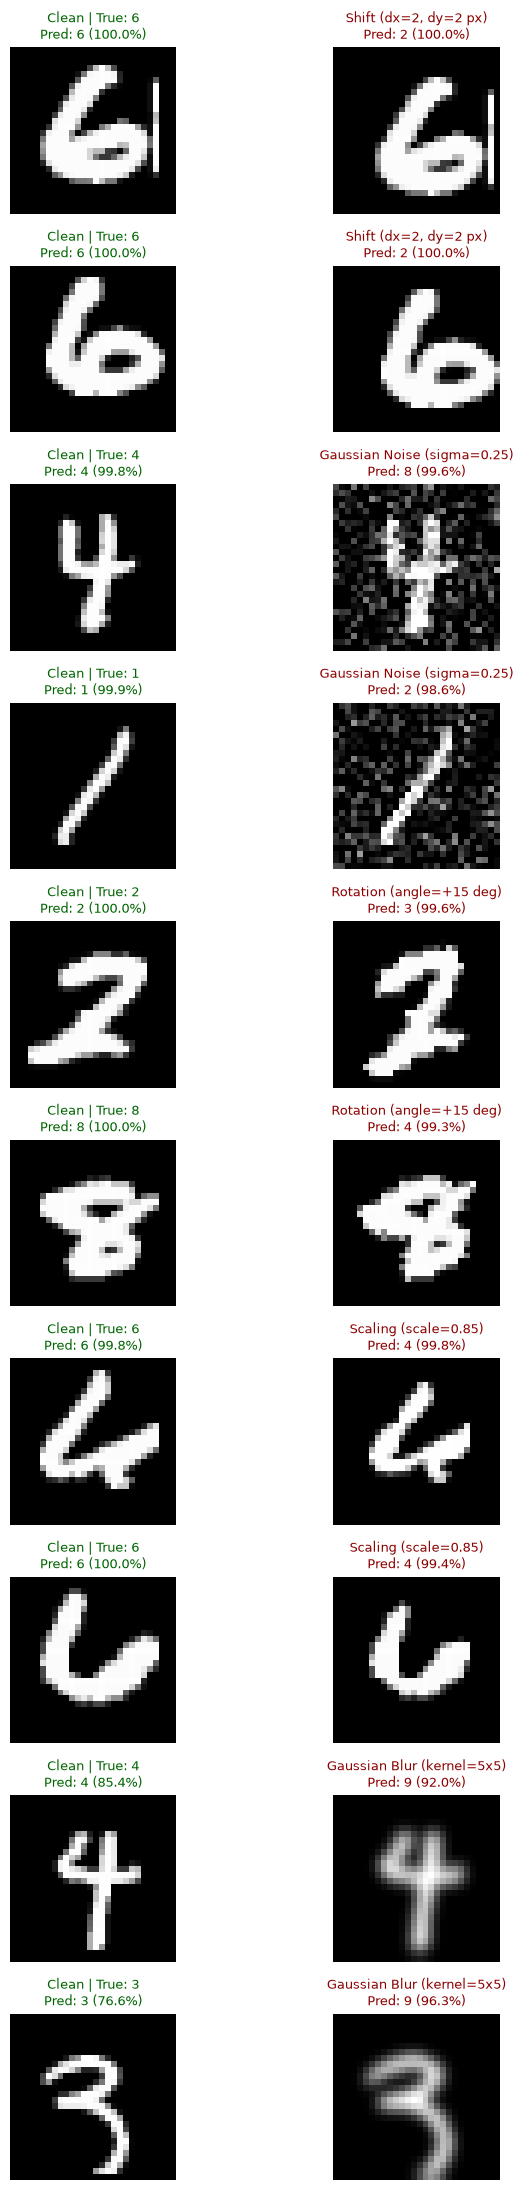

In [8]:
import os
import matplotlib.pyplot as plt
import torch
from fuzzer import Fuzzer
fuzzer = Fuzzer(model=eval_model, device=eval_device)
os.makedirs("results/violations", exist_ok=True)

transform_configs = [
    {
        "name": "Shift",
        "fn": Fuzzer.transform_shift,
        "param": (2, 2),
        "desc": "dx=2, dy=2 px"
    },
    {
        "name": "Gaussian Noise",
        "fn": Fuzzer.transform_noise,
        "param": 0.25,
        "desc": "sigma=0.25"
    },
    {
        "name": "Rotation",
        "fn": Fuzzer.transform_rotate,
        "param": 15.0,
        "desc": "angle=+15 deg"
    },
    {
        "name": "Scaling",
        "fn": Fuzzer.transform_scaling,
        "param": 0.85,
        "desc": "scale=0.85"
    },
    {
        "name": "Gaussian Blur",
        "fn": Fuzzer.transform_blur,
        "param": 5,
        "desc": "kernel=5x5"
    }
]

all_selected_violations = []
print("Поиск контрастных метаморфических нарушений...")
for cfg in transform_configs:
    top_bugs = fuzzer.find_top_violations(
        test_loader, 
        cfg["fn"], 
        param_val=cfg["param"], 
        top_k=2
    )
    for bug in top_bugs:
        bug["trans_name"] = cfg["name"]
        bug["trans_desc"] = cfg["desc"]
        all_selected_violations.append(bug)

print(f"Успешно собрано нарушений: {len(all_selected_violations)} шт.")

fig, axes = plt.subplots(nrows=10, ncols=2, figsize=(8, 22))
for i, bug in enumerate(all_selected_violations):
    clean_img = bug['clean_img'].squeeze().numpy()
    axes[i, 0].imshow(clean_img, cmap="gray")
    axes[i, 0].set_title(
        f"Clean | True: {bug['label']}\nPred: {bug['clean_pred']} ({bug['clean_prob']*100:.1f}%)",
        fontsize=9, color="darkgreen"
    )
    axes[i, 0].axis("off")
    trans_img = bug["trans_img"].squeeze().numpy()
    axes[i, 1].imshow(trans_img, cmap="gray")
    axes[i, 1].set_title(
        f"{bug['trans_name']} ({bug['trans_desc']})\nPred: {bug['trans_pred']} ({bug['trans_prob']*100:.1f}%)",
        fontsize=9, color="darkred"
    )
    axes[i, 1].axis("off")

plt.tight_layout()
save_path = "results/violations/top_10_violations.png"
plt.savefig(save_path, dpi=300)
print(f"График нарушений сохранен в {save_path}")
plt.show()


Обработка: Shift (dx, dy)...
Обработка: Additive Gaussian Noise...
Обработка: Rotation...
Обработка: Scaling...
Обработка: Gaussian Blur...
Все расчеты завершены.
График сохранен в results/curves.png


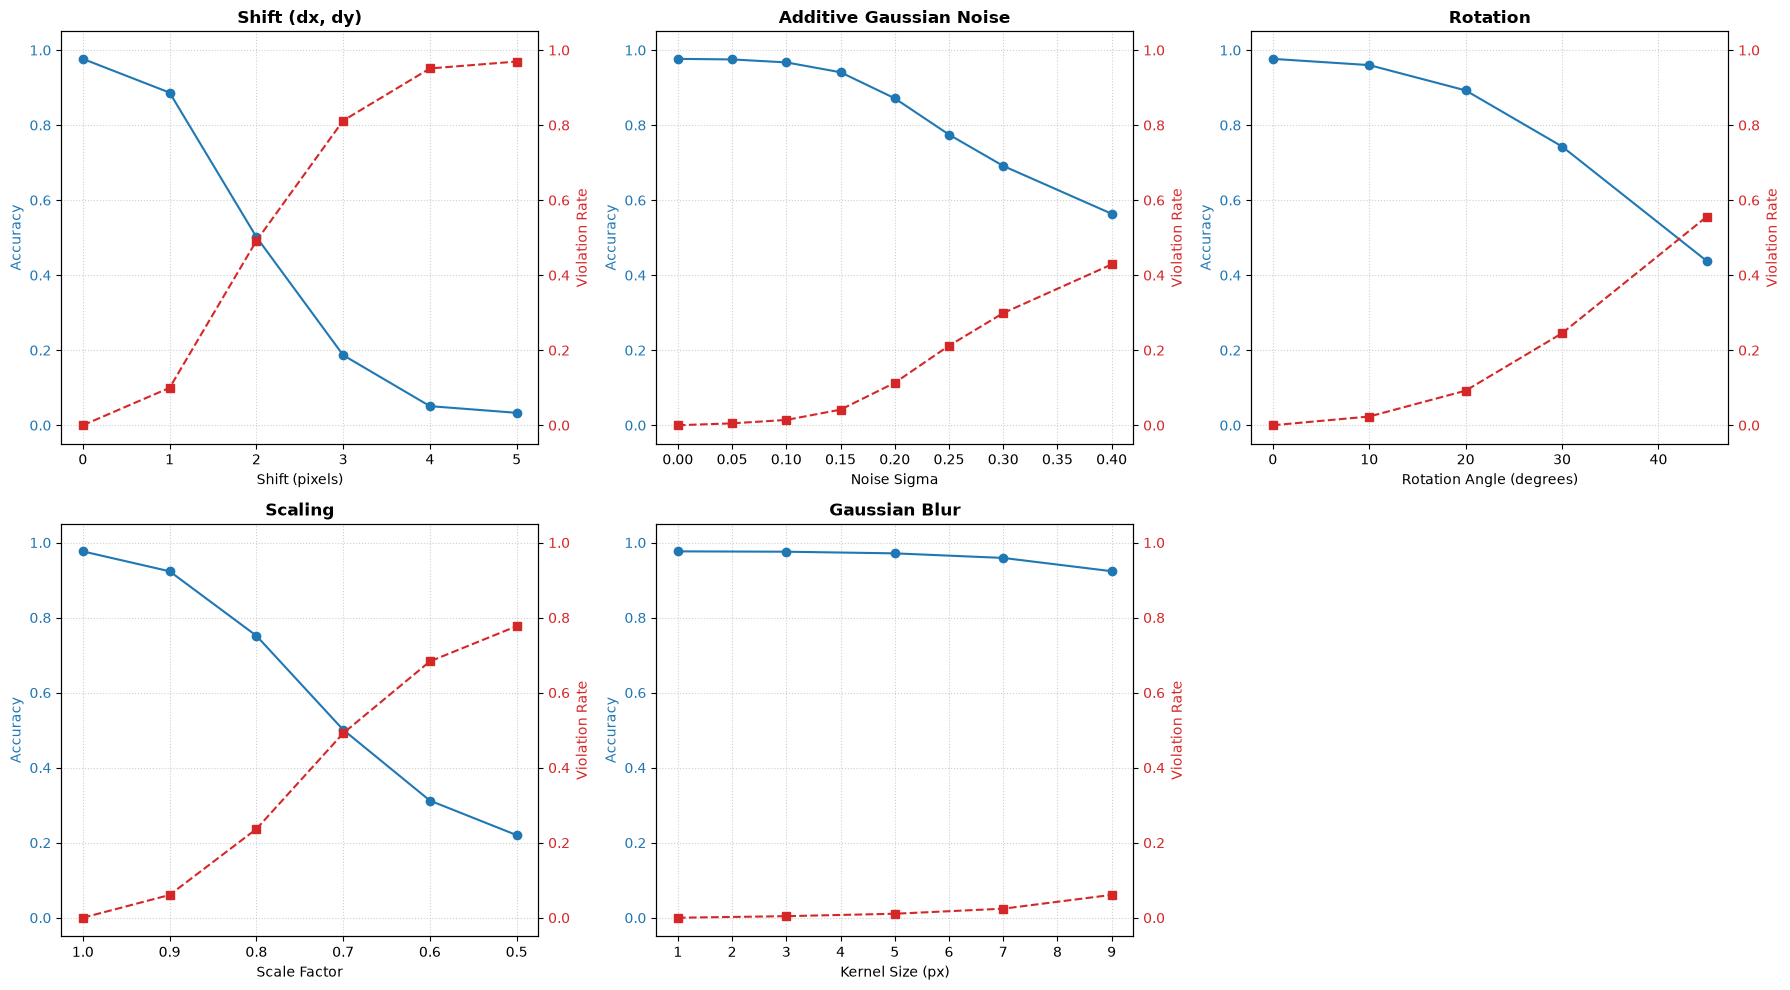

In [9]:
experiments = [
    {
        "name": "Shift (dx, dy)",
        "fn": Fuzzer.transform_shift,
        "grid": [(i, i) for i in range(0, 6)],  
        "x_vals": list(range(0, 6)),
        "xlabel": "Shift (pixels)"
    },
    {
        "name": "Additive Gaussian Noise",
        "fn": Fuzzer.transform_noise,
        "grid": [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4],
        "x_vals": [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4],
        "xlabel": "Noise Sigma"
    },
    {
        "name": "Rotation",
        "fn": Fuzzer.transform_rotate,
        "grid": [0, 10, 20, 30, 45],
        "x_vals": [0, 10, 20, 30, 45],
        "xlabel": "Rotation Angle (degrees)"
    },
    {
        "name": "Scaling",
        "fn": Fuzzer.transform_scaling,
        "grid": [1.0, 0.9, 0.8, 0.7, 0.6, 0.5],
        "x_vals": [1.0, 0.9, 0.8, 0.7, 0.6, 0.5],
        "xlabel": "Scale Factor"
    },
    {
        "name": "Gaussian Blur",
        "fn": Fuzzer.transform_blur,
        "grid": [1, 3, 5, 7, 9],
        "x_vals": [1, 3, 5, 7, 9],
        "xlabel": "Kernel Size (px)"
    }
]
curves_data = {}
for exp in experiments:
    print(f"Обработка: {exp['name']}...")
    res = fuzzer.run_parameter_grid(test_loader, exp["fn"], exp["grid"])
    curves_data[exp["name"]] = {
        "x": exp["x_vals"],
        "acc": res["accuracies"],
        "violation": res["violation_rates"],
        "xlabel": exp["xlabel"]
    }

print("Все расчеты завершены.")
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
axes = axes.flatten()
for i, (name, data) in enumerate(curves_data.items()):
    ax1 = axes[i]
    ax2 = ax1.twinx()
    line1 = ax1.plot(data["x"], data["acc"], color="tab:blue", marker="o", label="Accuracy")
    ax1.set_ylabel("Accuracy", color="tab:blue")
    ax1.tick_params(axis="y", labelcolor="tab:blue")
    ax1.set_ylim(-0.05, 1.05)

    line2 = ax2.plot(data["x"], data["violation"], color="tab:red", marker="s", linestyle="--", label="Violation Rate")
    ax2.set_ylabel("Violation Rate", color="tab:red")
    ax2.tick_params(axis="y", labelcolor="tab:red")
    ax2.set_ylim(-0.05, 1.05)

    ax1.set_title(name, fontsize=12, fontweight="bold")
    ax1.set_xlabel(data["xlabel"])
    ax1.grid(True, linestyle=":", alpha=0.6)

axes[5].axis('off')
axes[3].invert_xaxis()
plt.tight_layout()
save_path = "results/curves.png"
plt.savefig(save_path, dpi=300)
print(f"График сохранен в {save_path}")
plt.show()

In [10]:
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2

train_transform_alb = A.Compose([
    A.Affine(
        scale=(0.85, 1.15),
        translate_percent=(-0.08, 0.08), 
        rotate=(-15, 15),
        border_mode=cv2.BORDER_CONSTANT,
        p=0.7
    ),
    A.GaussNoise(std_range=(0.005, 0.15), p=0.4),
    A.GaussianBlur(blur_limit=(3, 5), p=0.3),
    ToTensorV2() 
])

class AugmentedMNIST(Dataset):

    def __init__(self, mnist_dataset, transform=None):
        self.dataset = mnist_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, label = self.dataset[idx]
        image_np = np.array(image, dtype=np.float32) / 255.0
        if self.transform:
            augmented = self.transform(image=image_np)
            image_tensor = augmented["image"]
        else:
            image_tensor = torch.from_numpy(image_np).unsqueeze(0)

        return image_tensor, label



raw_train_dataset = datasets.MNIST(root="./data", train=True, download=True)
alb_train_dataset = AugmentedMNIST(raw_train_dataset, transform=train_transform_alb)
alb_train_loader = DataLoader(alb_train_dataset, batch_size=64, shuffle=True)


In [11]:
new_model = BaseMLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(new_model.parameters(), lr=1e-3)
epochs = 5
print("Обучение MLP с аугментациями...")
for epoch in range(1, epochs + 1):
    new_model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in alb_train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = new_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    print(f"Эпоха [{epoch}/{epochs}] — Train Loss: {running_loss / total:.4f}, Train Acc: {correct / total * 100:.2f}%")

torch.save(new_model.state_dict(), "results/new_mlp.pt")

new_model.eval()
h_preds, h_targets = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = new_model(images)
        h_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        h_targets.extend(labels.numpy())

h_acc = accuracy_score(h_targets, h_preds)
h_prec, h_rec, h_f1, _ = precision_recall_fscore_support(h_targets, h_preds, average='macro')

print("=" * 45)
print(f"New Test Accuracy:   {h_acc * 100:.2f}%")
print(f"New Precision:       {h_prec:.4f}")
print(f"New Recall:          {h_rec:.4f}")
print(f"New Macro-F1:        {h_f1:.4f}")
print("=" * 45)


Обучение MLP с аугментациями...
Эпоха [1/5] — Train Loss: 0.6230, Train Acc: 81.72%
Эпоха [2/5] — Train Loss: 0.3111, Train Acc: 90.93%
Эпоха [3/5] — Train Loss: 0.2206, Train Acc: 93.53%
Эпоха [4/5] — Train Loss: 0.1817, Train Acc: 94.59%
Эпоха [5/5] — Train Loss: 0.1612, Train Acc: 95.23%
New Test Accuracy:   97.80%
New Precision:       0.9780
New Recall:          0.9777
New Macro-F1:        0.9778


Запуск сравнительного тестирования устойчивости под фаззером...
Обработка: Shift...
Обработка: Additive Gaussian Noise...
Обработка: Rotation...
Обработка: Scaling...
Обработка: Gaussian Blur...


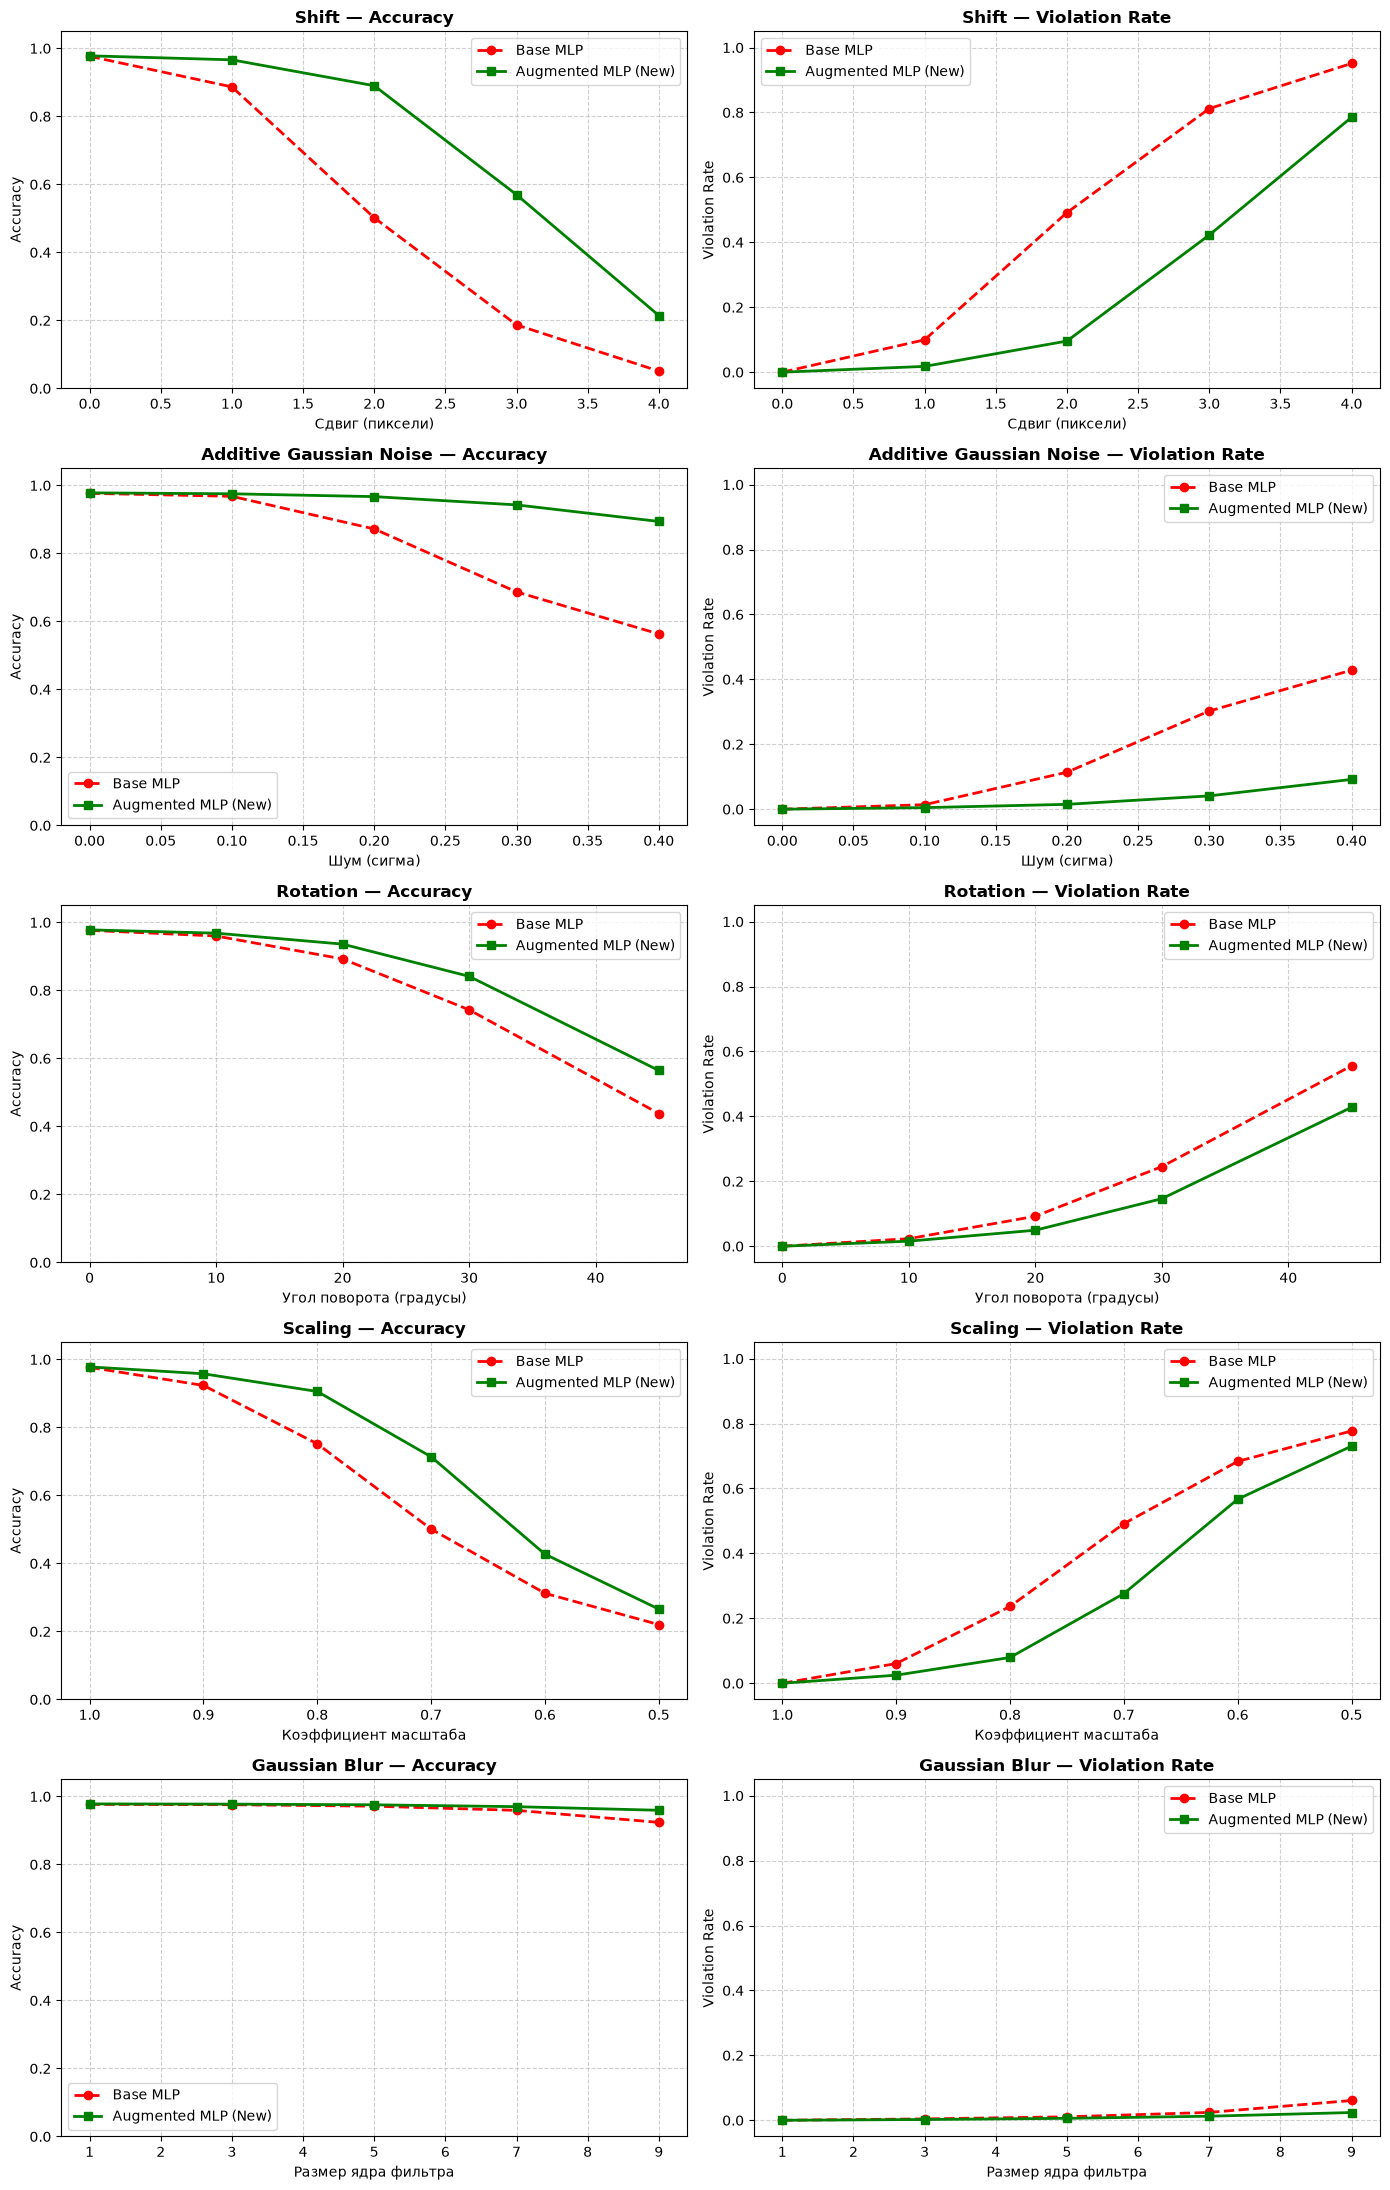

Сравнительные графики успешно сохранены в results/comparison_curves.png


In [12]:
fuzzer_base = Fuzzer(model=eval_model, device=device)
fuzzer_new  = Fuzzer(model=new_model, device=device)
experiments = [
    {
        "title": "Shift",
        "fn": Fuzzer.transform_shift,
        "grid": [(0, 0), (1, 1), (2, 2), (3, 3), (4, 4)],
        "x": [0, 1, 2, 3, 4],
        "xlabel": "Сдвиг (пиксели)"
    },
    {
        "title": "Additive Gaussian Noise",
        "fn": Fuzzer.transform_noise,
        "grid": [0.0, 0.1, 0.2, 0.3, 0.4],
        "x": [0.0, 0.1, 0.2, 0.3, 0.4],
        "xlabel": "Шум (сигма)"
    },
    {
        "title": "Rotation",
        "fn": Fuzzer.transform_rotate,
        "grid": [0, 10, 20, 30, 45],
        "x": [0, 10, 20, 30, 45],
        "xlabel": "Угол поворота (градусы)"
    },
    {
        "title": "Scaling",
        "fn": Fuzzer.transform_scaling,
        "grid": [1.0, 0.9, 0.8, 0.7, 0.6, 0.5],
        "x": [1.0, 0.9, 0.8, 0.7, 0.6, 0.5],
        "xlabel": "Коэффициент масштаба"
    },
    {
        "title": "Gaussian Blur",
        "fn": Fuzzer.transform_blur,
        "grid": [1, 3, 5, 7, 9],
        "x": [1, 3, 5, 7, 9],
        "xlabel": "Размер ядра фильтра"
    }
]
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(14, 22))
print("Запуск сравнительного тестирования устойчивости под фаззером...")
for idx, exp in enumerate(experiments):
    print(f"Обработка: {exp['title']}...")
    res_base = fuzzer_base.run_parameter_grid(test_loader, exp["fn"], exp["grid"])
    res_new  = fuzzer_new.run_parameter_grid(test_loader, exp["fn"], exp["grid"])
    x_vals = exp["x"]

    axes[idx, 0].plot(x_vals, res_base["accuracies"], 'r--o', label="Base MLP", linewidth=2)
    axes[idx, 0].plot(x_vals, res_new["accuracies"], 'g-s', label="Augmented MLP (New)", linewidth=2)
    axes[idx, 0].set_title(f"{exp['title']} — Accuracy", fontsize=12, fontweight="bold")
    axes[idx, 0].set_xlabel(exp["xlabel"], fontsize=10)
    axes[idx, 0].set_ylabel("Accuracy", fontsize=10)
    axes[idx, 0].set_ylim(0.0, 1.05)
    axes[idx, 0].grid(True, linestyle="--", alpha=0.6)
    axes[idx, 0].legend()

    axes[idx, 1].plot(x_vals, res_base["violation_rates"], 'r--o', label="Base MLP", linewidth=2)
    axes[idx, 1].plot(x_vals, res_new["violation_rates"], 'g-s', label="Augmented MLP (New)", linewidth=2)
    axes[idx, 1].set_title(f"{exp['title']} — Violation Rate", fontsize=12, fontweight="bold")
    axes[idx, 1].set_xlabel(exp["xlabel"], fontsize=10)
    axes[idx, 1].set_ylabel("Violation Rate", fontsize=10)
    axes[idx, 1].set_ylim(-0.05, 1.05)
    axes[idx, 1].grid(True, linestyle="--", alpha=0.6)
    axes[idx, 1].legend()

axes[3,0].invert_xaxis()
axes[3,1].invert_xaxis()
plt.tight_layout()
save_path = "results/comparison_curves.png"
plt.savefig(save_path, dpi=300)
plt.show()
print(f"Сравнительные графики успешно сохранены в {save_path}")


In [13]:
class BaseCNN(nn.Module):

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=5, stride=1, padding=2)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc_1 = nn.Linear(16 * 14 * 14, 128)
        self.fc_2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = torch.flatten(x, start_dim=1)
        x = F.relu(self.fc_1(x))
        return self.fc_2(x)

In [18]:
cnn_model = BaseCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=1e-3)
epochs = 5
print("Обучение CNN с аугментациями...")
for epoch in range(1, epochs+1):
    cnn_model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in alb_train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    print(f"Эпоха [{epoch}/{epochs}] — Train Loss: {running_loss / total:.4f}, Train Acc: {correct / total * 100:.2f}%")

torch.save(cnn_model.state_dict(), "results/cnn.pt")
cnn_model.eval()
h_preds, h_targets = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = cnn_model(images)
        h_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        h_targets.extend(labels.numpy())

h_acc = accuracy_score(h_targets, h_preds)
h_prec, h_rec, h_f1, _ = precision_recall_fscore_support(h_targets, h_preds, average='macro')

print("=" * 45)
print(f"CNN Test Accuracy:   {h_acc * 100:.2f}%")
print(f"CNN Precision:       {h_prec:.4f}")
print(f"CNN Recall:          {h_rec:.4f}")
print(f"CNN Macro-F1:        {h_f1:.4f}")
print("=" * 45)


Обучение CNN с аугментациями...
Эпоха [1/5] — Train Loss: 0.3926, Train Acc: 88.30%
Эпоха [2/5] — Train Loss: 0.1533, Train Acc: 95.49%
Эпоха [3/5] — Train Loss: 0.1218, Train Acc: 96.34%
Эпоха [4/5] — Train Loss: 0.1039, Train Acc: 96.89%
Эпоха [5/5] — Train Loss: 0.0898, Train Acc: 97.31%
CNN Test Accuracy:   98.92%
CNN Precision:       0.9891
CNN Recall:          0.9891
CNN Macro-F1:        0.9891


Запуск фаззинг-оценки для 3 моделей (Baseline MLP, Augmented MLP, Augmented CNN)...
Обработка: Shift...
Обработка: Additive Gaussian Noise...
Обработка: Rotation...
Обработка: Scaling...
Обработка: Gaussian Blur...


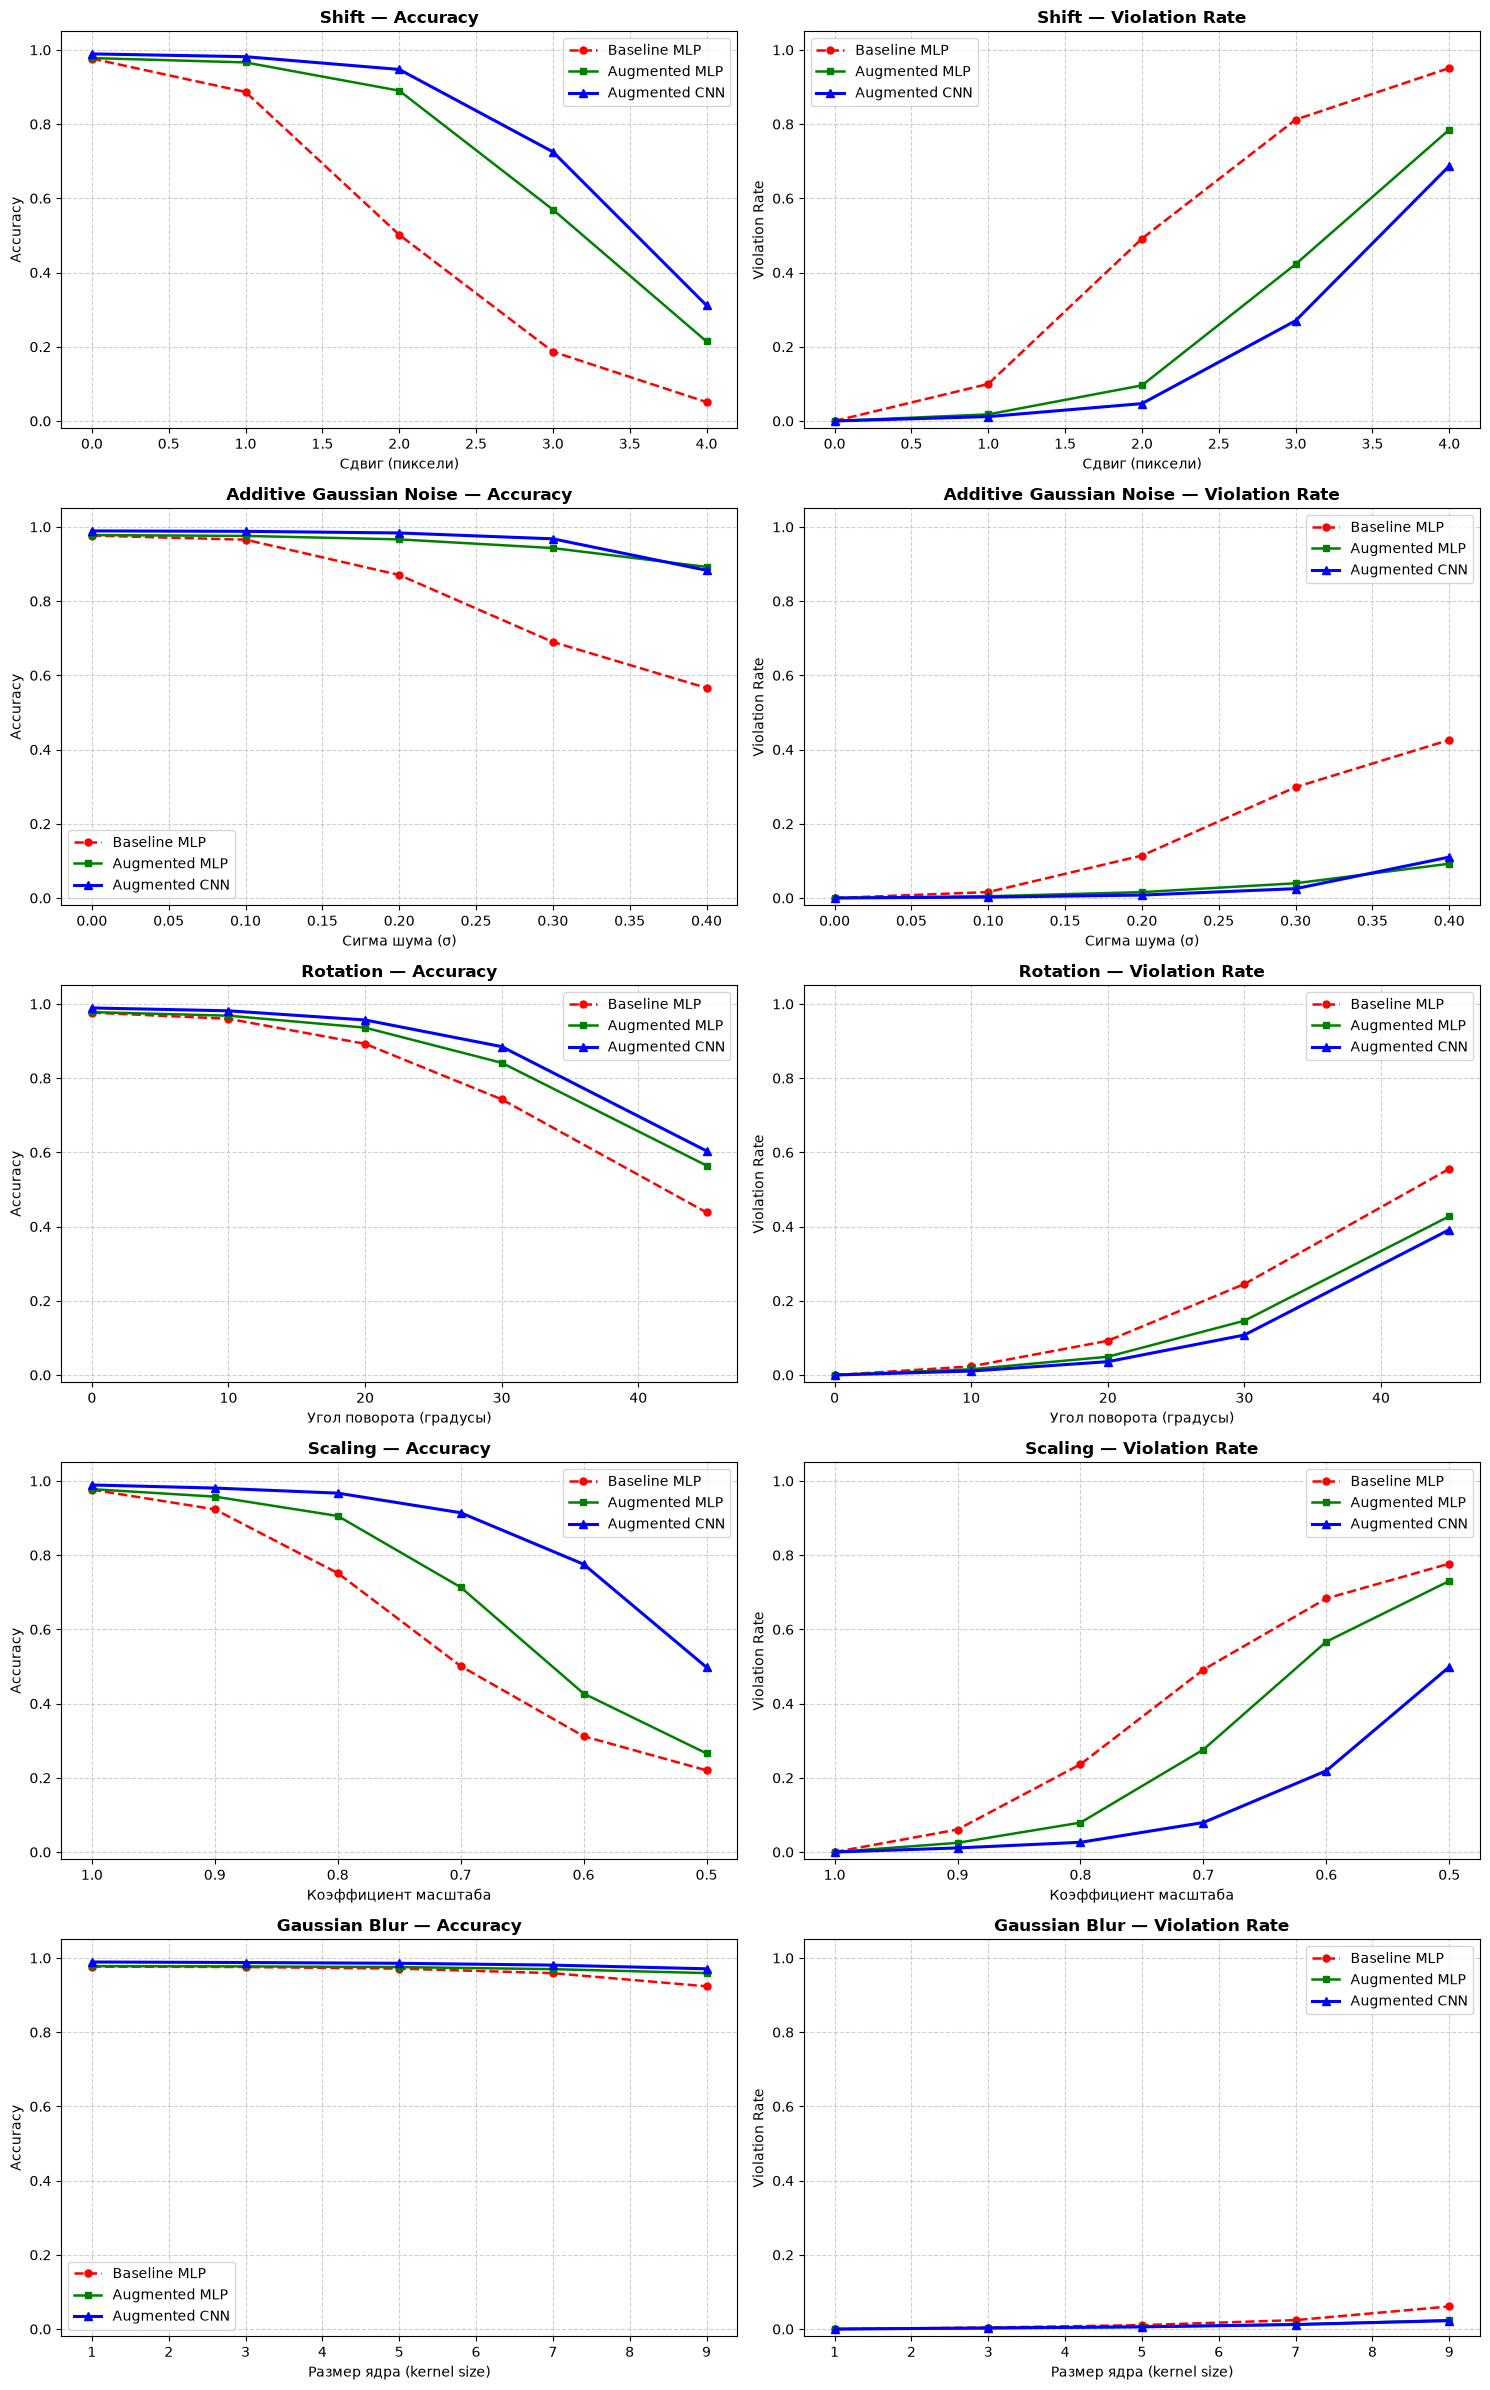


Все расчеты завершены. Итоговый график сохранен в: results/comparison_all_models.png


In [19]:
fuzzer_base = Fuzzer(model=eval_model, device=device)
fuzzer_mlp  = Fuzzer(model=new_model,  device=device)
fuzzer_cnn  = Fuzzer(model=cnn_model,  device=device)
experiments = [
    {
        "title": "Shift",
        "fn": Fuzzer.transform_shift,
        "grid": [(0, 0), (1, 1), (2, 2), (3, 3), (4, 4)],
        "x": [0, 1, 2, 3, 4],
        "xlabel": "Сдвиг (пиксели)"
    },
    {
        "title": "Additive Gaussian Noise",
        "fn": Fuzzer.transform_noise,
        "grid": [0.0, 0.1, 0.2, 0.3, 0.4],
        "x": [0.0, 0.1, 0.2, 0.3, 0.4],
        "xlabel": "Сигма шума (σ)"
    },
    {
        "title": "Rotation",
        "fn": Fuzzer.transform_rotate,
        "grid": [0, 10, 20, 30, 45],
        "x": [0, 10, 20, 30, 45],
        "xlabel": "Угол поворота (градусы)"
    },
    {
        "title": "Scaling",
        "fn": Fuzzer.transform_scaling,
        "grid": [1.0, 0.9, 0.8, 0.7, 0.6, 0.5],
        "x": [1.0, 0.9, 0.8, 0.7, 0.6, 0.5],
        "xlabel": "Коэффициент масштаба"
    },
    {
        "title": "Gaussian Blur",
        "fn": Fuzzer.transform_blur,
        "grid": [1, 3, 5, 7, 9],
        "x": [1, 3, 5, 7, 9],
        "xlabel": "Размер ядра (kernel size)"
    }
]
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(15, 24))

print("Запуск фаззинг-оценки для 3 моделей (Baseline MLP, Augmented MLP, Augmented CNN)...")

for idx, exp in enumerate(experiments):
    print(f"Обработка: {exp['title']}...")
    
    res_base = fuzzer_base.run_parameter_grid(test_loader, exp["fn"], exp["grid"])
    res_mlp  = fuzzer_mlp.run_parameter_grid(test_loader, exp["fn"], exp["grid"])
    res_cnn  = fuzzer_cnn.run_parameter_grid(test_loader, exp["fn"], exp["grid"])

    x_vals = exp["x"]

    axes[idx, 0].plot(x_vals, res_base["accuracies"], 'r--o', label="Baseline MLP", linewidth=1.8, markersize=5)
    axes[idx, 0].plot(x_vals, res_mlp["accuracies"],  'g-s',  label="Augmented MLP", linewidth=1.8, markersize=5)
    axes[idx, 0].plot(x_vals, res_cnn["accuracies"],  'b-^',  label="Augmented CNN", linewidth=2.2, markersize=6)
    
    axes[idx, 0].set_title(f"{exp['title']} — Accuracy", fontsize=12, fontweight="bold")
    axes[idx, 0].set_xlabel(exp["xlabel"], fontsize=10)
    axes[idx, 0].set_ylabel("Accuracy", fontsize=10)
    axes[idx, 0].set_ylim(-0.02, 1.05)
    axes[idx, 0].grid(True, linestyle="--", alpha=0.6)
    axes[idx, 0].legend()

    axes[idx, 1].plot(x_vals, res_base["violation_rates"], 'r--o', label="Baseline MLP", linewidth=1.8, markersize=5)
    axes[idx, 1].plot(x_vals, res_mlp["violation_rates"],  'g-s',  label="Augmented MLP", linewidth=1.8, markersize=5)
    axes[idx, 1].plot(x_vals, res_cnn["violation_rates"],  'b-^',  label="Augmented CNN", linewidth=2.2, markersize=6)
    
    axes[idx, 1].set_title(f"{exp['title']} — Violation Rate", fontsize=12, fontweight="bold")
    axes[idx, 1].set_xlabel(exp["xlabel"], fontsize=10)
    axes[idx, 1].set_ylabel("Violation Rate", fontsize=10)
    axes[idx, 1].set_ylim(-0.02, 1.05)
    axes[idx, 1].grid(True, linestyle="--", alpha=0.6)
    axes[idx, 1].legend()

axes[3,0].invert_xaxis()
axes[3,1].invert_xaxis()
plt.tight_layout()
save_path = "results/comparison_all_models.png"
plt.savefig(save_path, dpi=300)
plt.show()
print(f"\nВсе расчеты завершены. Итоговый график сохранен в: {save_path}")
